In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("retail_sales_dataset.csv")

In [4]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [5]:
print("Shape:", df.shape)

Shape: (1000, 9)


In [6]:
print("\nColumn Data Types:")
print(df.dtypes)



Column Data Types:
Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object


In [7]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [8]:
print("\nDuplicate Rows:", df.duplicated().sum())


Duplicate Rows: 0


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [10]:
df["Date"] = pd.to_datetime(df["Date"])

In [11]:
df["Month"] = df["Date"].dt.to_period("M")
df["Quarter"] = df["Date"].dt.to_period("Q")

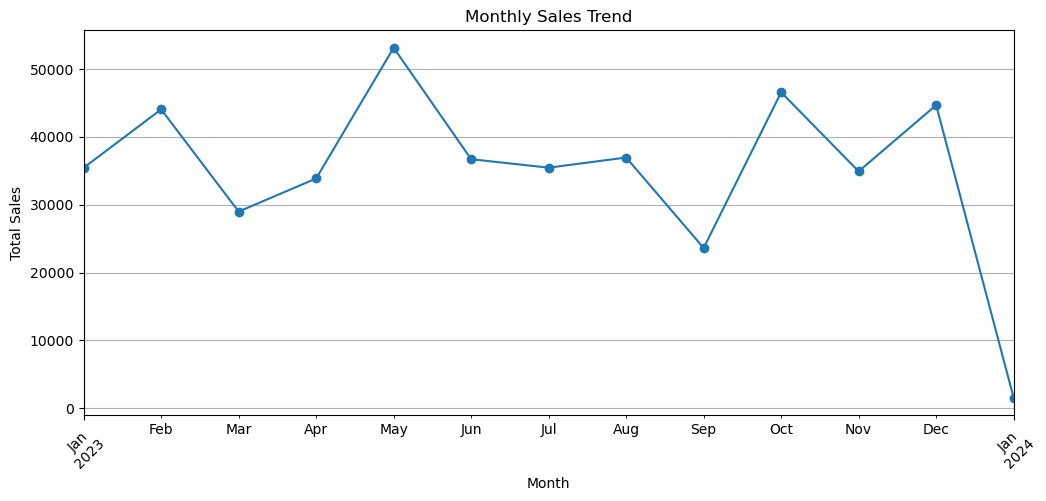

In [12]:
monthly_sales = df.groupby("Month")["Total Amount"].sum()

plt.figure(figsize=(12,5))
monthly_sales.plot(kind="line", marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

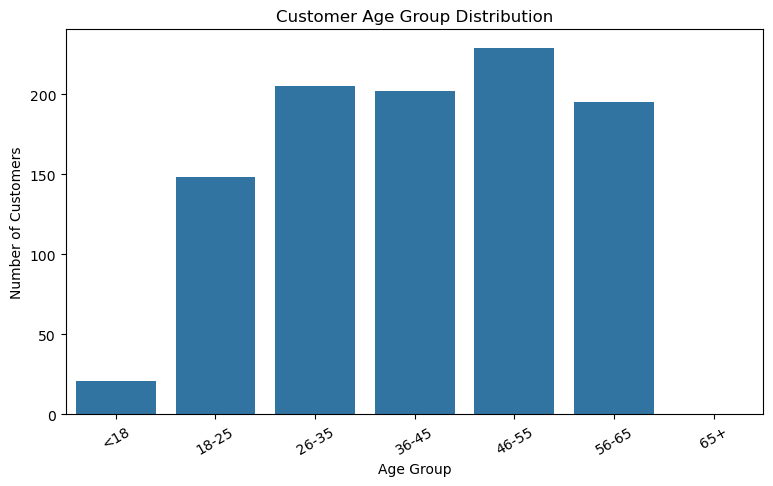

In [13]:
bins = [0, 18, 25, 35, 45, 55, 65, 100]
labels = ["<18", "18-25", "26-35", "36-45",
          "46-55", "56-65", "65+"]

df["Age Group"] = pd.cut(
    df["Age"],
    bins=bins,
    labels=labels
)

plt.figure(figsize=(9,5))
sns.countplot(data=df, x="Age Group")
plt.title("Customer Age Group Distribution")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.show()

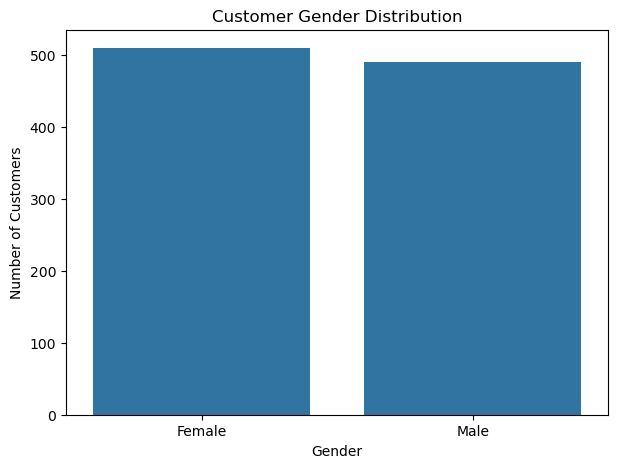

In [14]:
gender_counts = df["Gender"].value_counts()

plt.figure(figsize=(7,5))
sns.barplot(x=gender_counts.index, y=gender_counts.values)
plt.title("Customer Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.show()

In [17]:
top_products = df.groupby("Product Category")["Quantity"].sum()
top_products = top_products.sort_values(ascending=False).head(10)

print(top_products)

Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64


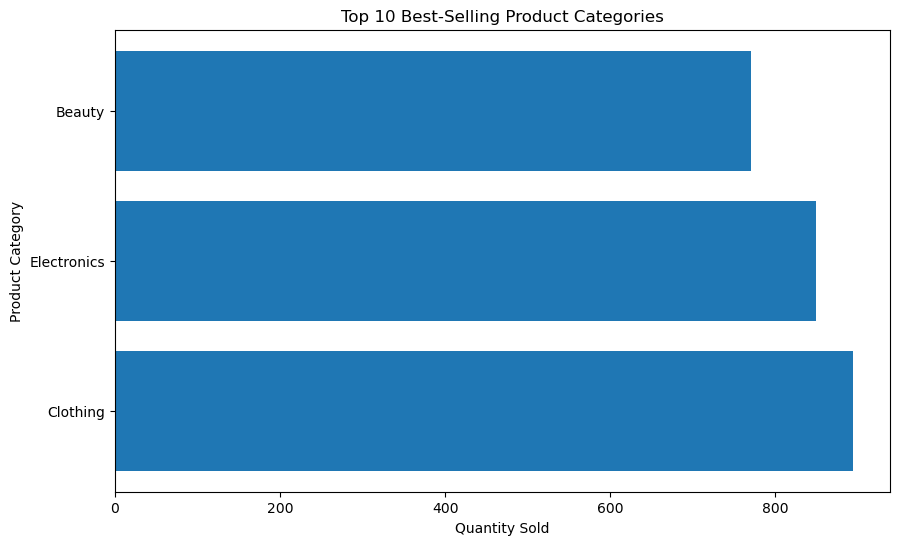

In [18]:
plt.figure(figsize=(10, 6))

plt.barh(top_products.index, top_products.values)

plt.title("Top 10 Best-Selling Product Categories")
plt.xlabel("Quantity Sold")
plt.ylabel("Product Category")

plt.show()

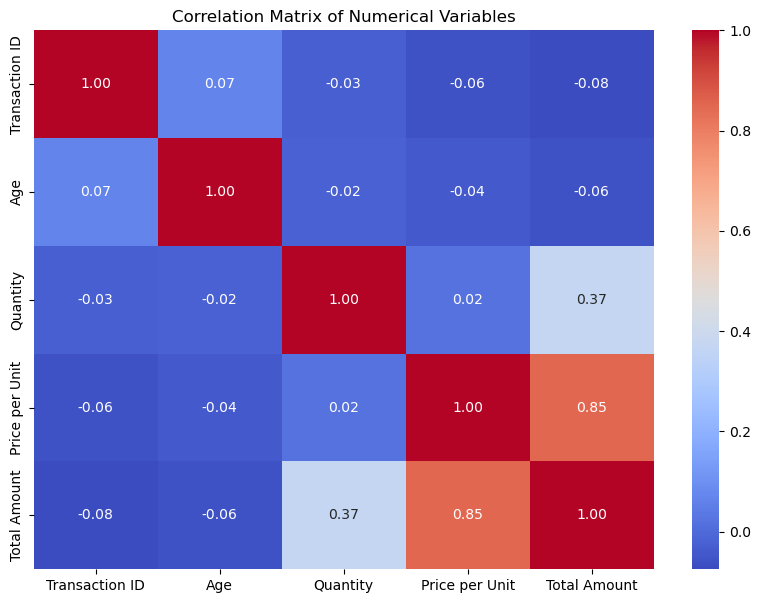

In [19]:
plt.figure(figsize=(10,7))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Variables")
plt.show()

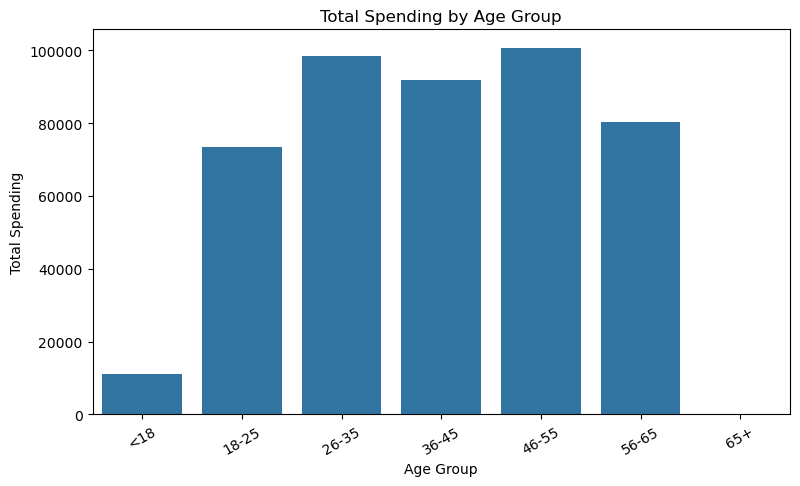

In [20]:
age_sales = (
    df.groupby("Age Group", observed=True)["Total Amount"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(9,5))

sns.barplot(
    data=age_sales,
    x="Age Group",
    y="Total Amount"
)

plt.title("Total Spending by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Total Spending")
plt.xticks(rotation=30)
plt.show()

Conclusion

The EDA helps identify important patterns in sales, customers, products, and revenue. The analysis can be used to understand customer behaviour and improve business decisions.

Actionable recommendations

1. Focus on high-performing products

Maintain sufficient stock of the top-selling products.
Monitor their demand regularly to reduce stock-outs.

2. Target high-value customer segments

Identify age groups that generate higher spending.
Create targeted offers and promotions for these segments.

3. Use seasonal sales patterns

Use monthly and quarterly trends to identify periods of high demand.
Increase inventory and marketing activities before expected high-sales periods.

4. Improve category-level strategy

Compare revenue across product categories.
Give more attention to categories with strong revenue while investigating categories with weaker performance.